# Model wyceny samochodów używanych – wersja MVP

Praca inżynierska: „Opracowanie modelu wyceny samochodów używanych na potrzeby
salonów samochodowych z wykorzystaniem uczenia maszynowego”.

Dane: Kaggle, S. Cyperski, „Car sales offers from otomoto.pl 2023”
(plik otomoto_offers_eng_23-04-2023.csv, 208 205 ofert, separator ';').

Kroki:
1. Wczytanie danych, filtrowanie (tylko samochody używane, ceny w PLN, usunięcie wartości skrajnych)
   i usunięcie duplikatów ogłoszeń.
2. Inżynieria cech (wiek, przebieg, moc, pojemność, województwo, liczba elementów wyposażenia...).
3. Podział na zbiór uczący i testowy (80/20).
4. Modele: model naiwny (mediana), regresja liniowa (Ridge), HistGradientBoosting, LightGBM
   (LightGBM: strojenie hiperparametrów i 5-krotna walidacja krzyżowa na zbiorze uczącym).
5. Ocena na zbiorze testowym: MAE, RMSE, MAPE, R².

Uruchomienie: `python mvp_model.py` (lub komórka po komórce w VS Code / Jupyter).
Strojenie hiperparametrów jest domyślnie wyłączone (trwa kilkadziesiąt minut); włącza je
zmienna środowiskowa RUN_TUNING=1 albo ustawienie RUN_TUNING = True poniżej.
Wymagane biblioteki: pandas, numpy, scikit-learn, lightgbm, matplotlib, joblib.

In [1]:
import os
import re
import time
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Ścieżki: plik CSV leży katalog wyżej niż ten skrypt; wyniki trafiają do model/results.
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_PATH = BASE_DIR.parent / "otomoto_offers_eng_23-04-2023.csv"
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5  # liczba podziałów w walidacji krzyżowej
RUN_TUNING = os.environ.get("RUN_TUNING", "0") == "1"  # losowe przeszukiwanie hiperparametrów LightGBM
N_TUNING_TRIALS = 30
warnings.filterwarnings("ignore", message=".*eval_set.*")  # LightGBM >= 4.7: ostrzeżenie o nazwie argumentu
REFERENCE_YEAR = 2023  # rok pobrania ofert – od niego liczymy wiek auta

## 1. Wczytanie i filtrowanie danych

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep=";", low_memory=False)
print(f"Wczytano: {df_raw.shape[0]:,} wierszy, {df_raw.shape[1]} kolumn")


def to_number(series: pd.Series) -> pd.Series:
    """Zamienia tekst typu '304 000 km', '1 998 cm3', '6,40 l/100km' na liczbę.

    Bierzemy tylko liczbę z początku tekstu – cyfry z jednostki ('cm3', 'l/100km') nie należą do wartości.
    """
    s = series.astype("string").str.extract(r"^\s*([\d\s.,]+)", expand=False)
    s = s.str.replace(r"\s", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce").astype(float)


df = df_raw.copy()
df["mileage_km"] = to_number(df["mileage"])
df["engine_cm3"] = to_number(df["engine_displacement"])
df["power_km"] = to_number(df["power"])
df["fuel_city_l100"] = to_number(df["fuel_consumption_in_city"])

# Filtry odpowiadające zastosowaniu w salonie (wycena aut używanych z rynku):
n0 = len(df)
filters = {
    "tylko samochody używane": df["state"] == "Used",
    "cena w PLN": df["currency"] == "PLN",
    "cena 2 000 – 1 500 000 PLN": df["price"].between(2_000, 1_500_000),
    "rok produkcji 1990–2023": df["production_year"].between(1990, 2023),
    "przebieg 1 – 1 000 000 km": df["mileage_km"].between(1, 1_000_000),
    "moc 30 – 1 000 KM lub brak": df["power_km"].between(30, 1_000) | df["power_km"].isna(),
    "paliwo inne niż wodór": df["fuel_type"] != "Hydrogen",
}
mask = pd.Series(True, index=df.index)
filter_log = []
for name, cond in filters.items():
    before = mask.sum()
    mask &= cond
    filter_log.append((name, int(before - mask.sum())))
df = df[mask].copy()
print(pd.DataFrame(filter_log, columns=["filtr", "usunięto wierszy"]).to_string(index=False))
print(f"Po filtrowaniu: {len(df):,} z {n0:,} ofert")

# Duplikaty ogłoszeń: to samo auto wystawione kilka razy (każde ogłoszenie ma własne id).
# Zostawiamy najnowsze ogłoszenie. Bez tego kroku to samo auto mogłoby trafić jednocześnie
# do zbioru uczącego i testowego, co zaniżałoby błąd na teście.
CAR_ID_COLS = [
    "vehicle_brand", "vehicle_model", "generation", "version", "production_year", "mileage",
    "engine_displacement", "power", "fuel_type", "transmission", "body_type", "color",
    "drive_type", "number_of_doors",
]
n_before = len(df)
df = df.sort_values(["offer_creation_date", "id"])
# 1) identyczny opis auta u tego samego sprzedawcy (ta sama lokalizacja)
df = df.drop_duplicates(subset=CAR_ID_COLS + ["location"], keep="last")
n_same_desc = n_before - len(df)
# 2) ten sam numer rejestracyjny (część numerów jest zamaskowana jako 'xxxxxxxxxx' – te pomijamy)
reg = df["vehicle_registration_number"].astype("string").str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
has_reg = reg.notna() & (reg.str.len() >= 4) & ~reg.str.fullmatch(r"X+")
same_reg = has_reg & df.assign(reg=reg).duplicated(subset=["reg", "vehicle_brand", "production_year"], keep="last")
df = df[~same_reg].sort_index()
print(f"Duplikaty: {n_same_desc} (ten sam opis i lokalizacja) + {int(same_reg.sum())} (ten sam nr rejestracyjny); "
      f"zostało {len(df):,} ofert")

Wczytano: 208,205 wierszy, 243 kolumn


                     filtr  usunięto wierszy
   tylko samochody używane             20690
                cena w PLN               375
cena 2 000 – 1 500 000 PLN               105
   rok produkcji 1990–2023              1373
 przebieg 1 – 1 000 000 km                14
moc 30 – 1 000 KM lub brak               368
     paliwo inne niż wodór                 1
Po filtrowaniu: 185,279 z 208,205 ofert


Duplikaty: 176 (ten sam opis i lokalizacja) + 477 (ten sam nr rejestracyjny); zostało 184,626 ofert


## 2. Inżynieria cech

In [3]:
VOIVODESHIPS = [
    "Dolnośląskie", "Kujawsko-pomorskie", "Lubelskie", "Lubuskie", "Łódzkie",
    "Małopolskie", "Mazowieckie", "Opolskie", "Podkarpackie", "Podlaskie",
    "Pomorskie", "Śląskie", "Świętokrzyskie", "Warmińsko-mazurskie",
    "Wielkopolskie", "Zachodniopomorskie",
]
voiv_regex = re.compile("|".join(VOIVODESHIPS))


def extract_voivodeship(loc: str) -> str:
    m = voiv_regex.search(str(loc))
    return m.group(0) if m else "nieznane"


df["voivodeship"] = df["location"].map(extract_voivodeship)
df["age"] = REFERENCE_YEAR - df["production_year"]
df["mileage_per_year"] = df["mileage_km"] / df["age"].clip(lower=1)

# Kolumny „Tak”/brak -> 1/0 (stan prawny i historia pojazdu)
YES_FLAGS = [
    "registered_in_poland", "first_owner_from_new", "no_accident", "serviced_at_aso",
    "damaged", "vat_margin", "vat", "leasing", "financing_possibility",
    "has_a_registration_number", "particulate_filter", "tuning",
]
for c in YES_FLAGS:
    df[c] = df[c].eq("Tak").astype(int)

# Wyposażenie: 181 kolumn z wartością True lub pustą. Liczymy elementy wyposażenia
# i dodatkowo zachowujemy wszystkie flagi jako cechy 0/1.
EQUIPMENT_COLS = [
    c for c in df_raw.columns
    if df_raw[c].dtype == object and set(df_raw[c].dropna().unique()) <= {True}
]
equip = df[EQUIPMENT_COLS].notna().astype(np.int8)
equip.columns = ["eq_" + c for c in EQUIPMENT_COLS]
df = pd.concat([df, equip], axis=1)
df["equipment_count"] = equip.sum(axis=1)
print(f"Kolumn wyposażenia: {len(EQUIPMENT_COLS)}")

# Zbiór cech wejściowych modelu
CAT_COLS = [
    "vehicle_brand", "vehicle_model", "generation", "fuel_type", "transmission",
    "body_type", "drive_type", "color", "color_type", "seller_type",
    "country_of_origin", "voivodeship",
]
NUM_COLS = [
    "age", "mileage_km", "mileage_per_year", "engine_cm3", "power_km",
    "fuel_city_l100", "number_of_doors", "number_of_seats", "equipment_count",
] + YES_FLAGS
EQ_COLS = list(equip.columns)

for c in CAT_COLS:
    df[c] = df[c].fillna("brak").astype(str)

X = df[CAT_COLS + NUM_COLS + EQ_COLS]
y = df["price"].astype(float)
y_log = np.log(y)  # modelujemy log(ceny) – rozkład cen jest silnie prawostronnie skośny

Kolumn wyposażenia: 181


## 2a. Opis danych: statystyki, rozkład cen, cena a wiek auta

                 braki [%]     count      mean      std     min      25%       50%       75%        max
price                  0.0  184626.0   69428.9  86408.3  2000.0  23500.0   44430.0   82900.0  1500000.0
age                    0.0  184626.0       9.9      5.7     0.0      5.0       9.0      14.0       33.0
mileage_km             0.0  184626.0  155660.2  90066.7     1.0  85000.0  156000.0  216000.0  1000000.0
power_km               0.0  184607.0     160.0     83.2    31.0    110.0     140.0     184.0     1000.0
engine_cm3             0.9  182920.0    1926.0    762.0   400.0   1498.0    1896.0    1997.0     8400.0
equipment_count        0.0  184626.0      34.9     22.5     0.0     20.0      32.0      47.0      148.0


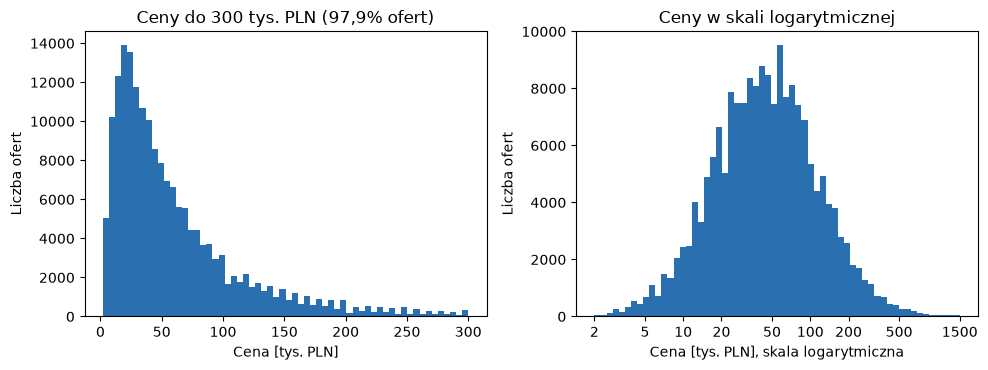

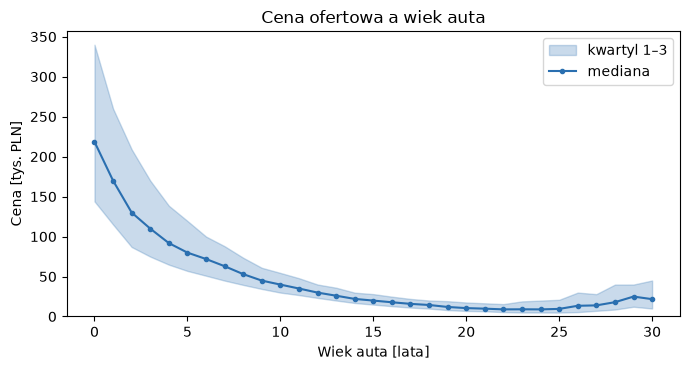

In [4]:
summary = df[["price", "age", "mileage_km", "power_km", "engine_cm3", "equipment_count"]].describe(
    percentiles=[0.25, 0.5, 0.75]).T
summary.insert(0, "braki [%]", df[summary.index].isna().mean() * 100)
print(summary.round(1).to_string())
summary.round(1).to_csv(RESULTS_DIR / "data_summary.csv", sep=";", decimal=",")

# Rozkład cen: skala liniowa (ucięta na 300 tys. PLN) i logarytmiczna
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(y[y <= 300_000] / 1000, bins=60, color="#2a6fb0")
axes[0].set(xlabel="Cena [tys. PLN]", ylabel="Liczba ofert",
            title="Ceny do 300 tys. PLN (" + f"{(y <= 300_000).mean() * 100:.1f}".replace(".", ",") + "% ofert)")
axes[1].hist(np.log10(y), bins=60, color="#2a6fb0")
ticks = [2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000, 500_000, 1_500_000]
axes[1].set_xticks(np.log10(ticks))
axes[1].set_xticklabels([f"{v // 1000}" for v in ticks])
axes[1].set(xlabel="Cena [tys. PLN], skala logarytmiczna", ylabel="Liczba ofert", title="Ceny w skali logarytmicznej")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "price_distribution.png", dpi=150)

# Cena a wiek auta: mediana i rozstęp międzykwartylowy
by_age = df[df["age"] <= 30].groupby("age")["price"].quantile([0.25, 0.5, 0.75]).unstack() / 1000
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.fill_between(by_age.index, by_age[0.25], by_age[0.75], color="#2a6fb0", alpha=0.25, label="kwartyl 1–3")
ax.plot(by_age.index, by_age[0.5], color="#2a6fb0", marker="o", ms=3, label="mediana")
ax.set(xlabel="Wiek auta [lata]", ylabel="Cena [tys. PLN]", title="Cena ofertowa a wiek auta", ylim=(0, None))
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "price_vs_age.png", dpi=150)

## 3. Podział na zbiór uczący i testowy

In [5]:
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.2, random_state=RANDOM_STATE
)
y_train, y_test = np.exp(y_train_log), np.exp(y_test_log)
print(f"Zbiór uczący: {len(X_train):,}, testowy: {len(X_test):,}")

Zbiór uczący: 147,700, testowy: 36,926


## 4. Modele

In [6]:
def evaluate(name: str, y_true: np.ndarray, y_pred: np.ndarray, seconds: float) -> dict:
    """Miary błędu liczone w złotówkach (po powrocie z log-skali)."""
    return {
        "model": name,
        "MAE [PLN]": mean_absolute_error(y_true, y_pred),
        "RMSE [PLN]": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE [%]": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "MdAPE [%]": np.median(np.abs((y_true - y_pred) / y_true)) * 100,
        "R2": r2_score(y_true, y_pred),
        "czas uczenia [s]": seconds,
    }


results, predictions = [], {}

# 4.0 Model naiwny: mediana ceny dla pary marka + model (punkt odniesienia)
t = time.time()
train_df = X_train[["vehicle_brand", "vehicle_model"]].assign(logp=y_train_log.values)
med_bm = train_df.groupby(["vehicle_brand", "vehicle_model"])["logp"].median()
med_b = train_df.groupby("vehicle_brand")["logp"].median()
key = pd.MultiIndex.from_frame(X_test[["vehicle_brand", "vehicle_model"]])
pred = pd.Series(med_bm.reindex(key).values, index=X_test.index)
pred = pred.fillna(X_test["vehicle_brand"].map(med_b)).fillna(y_train_log.median())
predictions["Mediana (marka+model)"] = np.exp(pred.values)
results.append(evaluate("Mediana (marka+model)", y_test, predictions["Mediana (marka+model)"], time.time() - t))

# 4.1 Regresja liniowa z regularyzacją (Ridge), zmienne kategoryczne -> one-hot
linear = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), CAT_COLS),
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), NUM_COLS),
        ("eq", "passthrough", EQ_COLS),
    ])),
    ("model", Ridge(alpha=1.0)),
])
t = time.time()
linear.fit(X_train, y_train_log)
predictions["Regresja liniowa (Ridge)"] = np.exp(linear.predict(X_test))
results.append(evaluate("Regresja liniowa (Ridge)", y_test, predictions["Regresja liniowa (Ridge)"], time.time() - t))

# 4.2 HistGradientBoosting (scikit-learn), kategorie zakodowane porządkowo
hgb = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                               encoded_missing_value=-1), CAT_COLS),
    ], remainder="passthrough")),
    ("model", HistGradientBoostingRegressor(
        max_iter=1000, learning_rate=0.1, max_leaf_nodes=63,
        categorical_features=list(range(len(CAT_COLS))),
        early_stopping=True, random_state=RANDOM_STATE,
    )),
])
# HGB obsługuje maks. 255 kategorii na cechę – rzadkie modele/generacje łączymy w „inne”
X_train_hgb, X_test_hgb = X_train.copy(), X_test.copy()
for c in CAT_COLS:
    top = X_train[c].value_counts().index[:250]
    X_train_hgb[c] = X_train[c].where(X_train[c].isin(top), "inne")
    X_test_hgb[c] = X_test[c].where(X_test[c].isin(top), "inne")
t = time.time()
hgb.fit(X_train_hgb, y_train_log)
predictions["HistGradientBoosting"] = np.exp(hgb.predict(X_test_hgb))
results.append(evaluate("HistGradientBoosting", y_test, predictions["HistGradientBoosting"], time.time() - t))

# 4.3 LightGBM – gradient boosting z natywną obsługą wielu kategorii (np. 1 000+ modeli aut)
X_train_lgb, X_test_lgb = X_train.copy(), X_test.copy()
for c in CAT_COLS:
    cats = pd.CategoricalDtype(sorted(X_train[c].unique()))
    X_train_lgb[c] = X_train[c].astype(cats)
    X_test_lgb[c] = X_test[c].where(X_test[c].isin(cats.categories)).astype(cats)  # nieznane w teście -> NaN

# Parametry stałe oraz parametry wyjściowe (MVP sprzed strojenia – punkt odniesienia)
LGBM_FIXED = dict(n_estimators=5000, subsample_freq=1, random_state=RANDOM_STATE, verbose=-1)
LGBM_PARAMS_MVP = dict(
    learning_rate=0.05, num_leaves=127, min_child_samples=20,
    subsample=0.8, colsample_bytree=0.8, cat_smooth=10,
)
# Parametry wybrane w strojeniu: najniższy MAPE w 5-krotnej walidacji krzyżowej
# (próba 27 w results/tuning_results.csv; model końcowy używa mniejszego kroku uczenia niż strojenie)
LGBM_PARAMS = dict(
    learning_rate=0.05, num_leaves=511, min_child_samples=5,
    subsample=1.0, colsample_bytree=0.4, reg_lambda=20.0, max_bin=511,
    cat_smooth=10, cat_l2=10.0, min_data_per_group=100,
    objective="huber", alpha=0.3,  # funkcja Hubera: mniejsza wrażliwość na nietypowe ceny
)


def cv_lightgbm(params: dict, X_cv: pd.DataFrame, y_cv_log: pd.Series, n_splits: int = N_SPLITS) -> pd.DataFrame:
    """Walidacja krzyżowa LightGBM na zbiorze uczącym (zbiór testowy nie bierze w niej udziału).

    W każdym podziale model uczy się na k-1 częściach, a część odłożona służy do wczesnego
    zatrzymania i do policzenia miar błędu w złotówkach.
    """
    rows = []
    folds = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    for fold, (tr, va) in enumerate(folds.split(X_cv), start=1):
        model = lgb.LGBMRegressor(**LGBM_FIXED, **params)
        t0 = time.time()
        model.fit(X_cv.iloc[tr], y_cv_log.iloc[tr],
                  eval_set=[(X_cv.iloc[va], y_cv_log.iloc[va])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        pred_va = np.exp(model.predict(X_cv.iloc[va]))
        row = evaluate(f"{fold}", np.exp(y_cv_log.iloc[va].values), pred_va, time.time() - t0)
        row["liczba drzew"] = model.best_iteration_
        rows.append(row)
    return pd.DataFrame(rows).rename(columns={"model": "podział"})


# 4.3a Strojenie hiperparametrów: losowe przeszukiwanie, każda konfiguracja oceniana w 5-krotnej CV.
# Dla szybkości przeszukiwanie używa learning_rate=0.1; model końcowy uczony jest z mniejszym krokiem.
TUNING_SPACE = {
    "num_leaves": [63, 127, 255, 511],
    "min_child_samples": [5, 10, 20, 40],
    "colsample_bytree": [0.3, 0.4, 0.5, 0.65, 0.8],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "reg_lambda": [0.0, 1.0, 5.0, 20.0],
    "max_bin": [255, 511, 1023],
    "cat_smooth": [5, 10, 30],
    "cat_l2": [1.0, 10.0, 30.0],
    "min_data_per_group": [50, 100, 200],
    "objective": ["regression", "huber"],  # huber: mniejsza wrażliwość na nietypowe ceny
}
if RUN_TUNING:
    rng = np.random.default_rng(RANDOM_STATE)
    trials = [dict(LGBM_PARAMS_MVP)]  # próba 0 = parametry MVP
    for _ in range(N_TUNING_TRIALS):
        trials.append({k: v[int(rng.integers(len(v)))] for k, v in TUNING_SPACE.items()})
    tuning_rows = []
    for i, params in enumerate(trials):
        params = {**params, "learning_rate": 0.1}
        if params.get("objective") == "huber":
            params["alpha"] = 0.3  # próg funkcji Hubera w skali log(ceny)
        cv = cv_lightgbm(params, X_train_lgb, y_train_log)
        row = {"próba": i, **{k: params.get(k) for k in TUNING_SPACE},
               **cv[["MAE [PLN]", "RMSE [PLN]", "MAPE [%]", "MdAPE [%]", "liczba drzew"]].mean().round(2).to_dict(),
               "czas [s]": round(cv["czas uczenia [s]"].sum())}
        tuning_rows.append(row)
        print(f"strojenie {i:2d}/{N_TUNING_TRIALS}: MAPE {row['MAPE [%]']:.2f}%  MAE {row['MAE [PLN]']:.0f}  {row['czas [s]']} s", flush=True)
        pd.DataFrame(tuning_rows).sort_values("MAPE [%]").to_csv(
            RESULTS_DIR / "tuning_results.csv", index=False, sep=";", decimal=",")
    print(pd.DataFrame(tuning_rows).sort_values("MAPE [%]").head(10).to_string(index=False))

# 4.3b Walidacja krzyżowa i model końcowy
cv_tables = {}


def cv_and_fit(name: str, params: dict, X_fit: pd.DataFrame, y_fit_log: pd.Series) -> lgb.LGBMRegressor:
    """5-krotna CV, a potem model uczony na całym podanym zbiorze (liczba drzew = średnia z CV)."""
    cv = cv_lightgbm(params, X_fit, y_fit_log)
    summary = cv.drop(columns="podział").agg(["mean", "std"]).rename(index={"mean": "średnia", "std": "odch. std."})
    cv_tables[name] = pd.concat([cv.set_index("podział"), summary]).round(2)
    print(f"{name}, {N_SPLITS}-krotna walidacja krzyżowa ({len(X_fit):,} ofert):")
    print(cv_tables[name].to_string())
    n_trees = int(round(cv["liczba drzew"].mean()))
    model = lgb.LGBMRegressor(**{**LGBM_FIXED, "n_estimators": n_trees}, **params)
    t0 = time.time()
    model.fit(X_fit, y_fit_log)
    model.fit_seconds_ = time.time() - t0
    return model


# Model z parametrami wyjściowymi (przed strojeniem) i model po strojeniu – oba na wszystkich ofertach
lgbm_mvp = cv_and_fit("LightGBM (parametry wyjściowe)", LGBM_PARAMS_MVP, X_train_lgb, y_train_log)
lgbm = cv_and_fit("LightGBM (po strojeniu)", LGBM_PARAMS, X_train_lgb, y_train_log)
for name, model in [("LightGBM (parametry wyjściowe)", lgbm_mvp), ("LightGBM (po strojeniu)", lgbm)]:
    predictions[name] = np.exp(model.predict(X_test_lgb))
    results.append(evaluate(name, y_test, predictions[name], model.fit_seconds_))

# 4.4 Wariant dla salonu: auta nieuszkodzone, nie starsze niż 15 lat.
# Ten sam podział na zbiór uczący i testowy – segment to podzbiór obu części.
SEGMENT_MAX_AGE = 15


def in_segment(frame: pd.DataFrame) -> pd.Series:
    return (frame["damaged"] == 0) & (frame["age"] <= SEGMENT_MAX_AGE)


seg_train, seg_test = in_segment(X_train), in_segment(X_test)
print(f"Segment salonu: {int(in_segment(X).sum()):,} z {len(X):,} ofert "
      f"(zbiór uczący {int(seg_train.sum()):,}, testowy {int(seg_test.sum()):,})")
lgbm_seg = cv_and_fit("LightGBM – model segmentowy", LGBM_PARAMS, X_train_lgb[seg_train], y_train_log[seg_train])
pred_seg = np.exp(lgbm_seg.predict(X_test_lgb[seg_test]))

LightGBM (parametry wyjściowe), 5-krotna walidacja krzyżowa (147,700 ofert):
            MAE [PLN]  RMSE [PLN]  MAPE [%]  MdAPE [%]    R2  czas uczenia [s]  liczba drzew
1             7490.48    20153.32     12.79       8.14  0.94             12.57        603.00
2             7602.45    21584.13     12.75       8.07  0.94             14.10        702.00
3             7409.10    19682.27     12.67       8.17  0.94             12.62        583.00
4             7646.98    21401.25     12.78       8.18  0.94             19.01       1085.00
5             7619.74    21674.51     12.62       8.06  0.94             11.74        648.00
średnia       7553.75    20899.10     12.72       8.12  0.94             14.01        724.20
odch. std.     100.43      916.45      0.07       0.06  0.00              2.92        206.82


LightGBM (po strojeniu), 5-krotna walidacja krzyżowa (147,700 ofert):
            MAE [PLN]  RMSE [PLN]  MAPE [%]  MdAPE [%]    R2  czas uczenia [s]  liczba drzew
1             7144.52    20455.22     12.36       7.69  0.94             37.04         855.0
2             7239.42    21577.61     12.34       7.65  0.94             41.64        1010.0
3             7042.88    19502.40     12.30       7.77  0.95             41.76         841.0
4             7269.22    20621.40     12.41       7.71  0.94             43.62        1034.0
5             7300.29    22379.75     12.27       7.77  0.93             43.41        1018.0
średnia       7199.27    20907.28     12.33       7.72  0.94             41.49         951.6
odch. std.     105.08     1104.23      0.05       0.05  0.01              2.65          95.1


Segment salonu: 141,152 z 184,626 ofert (zbiór uczący 112,965, testowy 28,187)


LightGBM – model segmentowy, 5-krotna walidacja krzyżowa (112,965 ofert):
            MAE [PLN]  RMSE [PLN]  MAPE [%]  MdAPE [%]    R2  czas uczenia [s]  liczba drzew
1             7511.25    20182.47      9.27       6.51  0.95             30.85        770.00
2             7948.77    24291.19      9.38       6.58  0.93             38.60        995.00
3             7853.65    23280.37      9.43       6.60  0.94             35.43        896.00
4             7531.56    21407.40      9.35       6.52  0.95             29.85        719.00
5             7702.76    22180.60      9.31       6.56  0.94             33.99        846.00
średnia       7709.60    22268.41      9.35       6.55  0.94             33.74        845.20
odch. std.     193.03     1598.12      0.06       0.04  0.01              3.53        107.94


## 5. Wyniki na zbiorze testowym

In [7]:
res = pd.DataFrame(results).round(2)
print(res.to_string(index=False))
res.to_csv(RESULTS_DIR / "metrics.csv", index=False, sep=";", decimal=",")
pd.concat(cv_tables, names=["wariant", "podział"]).to_csv(RESULTS_DIR / "cv_lightgbm.csv", sep=";", decimal=",")

# Model pełny i model segmentowy obok siebie (zbiór testowy)
best = "LightGBM (po strojeniu)"
seg_rows = [
    ("Model pełny – wszystkie oferty", y_test, predictions[best]),
    ("Model pełny – segment salonu", y_test[seg_test], predictions[best][seg_test.values]),
    ("Model segmentowy – segment salonu", y_test[seg_test], pred_seg),
]
seg_res = pd.DataFrame([
    {"wariant": name, "liczba ofert (test)": len(yt), **{k: v for k, v in evaluate(name, yt, yp, 0).items()
                                                        if k not in ("model", "czas uczenia [s]")}}
    for name, yt, yp in seg_rows
]).round(2)
print(seg_res.to_string(index=False))
seg_res.to_csv(RESULTS_DIR / "segment_comparison.csv", index=False, sep=";", decimal=",")

# Błąd najlepszego modelu w przedziałach cenowych (ważne dla salonu: auta tanie vs drogie)
bands = pd.cut(y_test, [0, 20_000, 50_000, 100_000, 200_000, np.inf],
               labels=["<20k", "20–50k", "50–100k", "100–200k", ">200k"])
err = pd.DataFrame({"band": bands, "y": y_test, "p": predictions[best]})
by_band = err.groupby("band", observed=True).apply(
    lambda g: pd.Series({
        "liczba ofert": len(g),
        "MAE [PLN]": mean_absolute_error(g.y, g.p),
        "MAPE [%]": np.mean(np.abs(g.y - g.p) / g.y) * 100,
    }), include_groups=False,
).round(1)
print(by_band)
by_band.to_csv(RESULTS_DIR / "error_by_price_band.csv", sep=";", decimal=",")

# Błąd modelu pełnego w grupach ofert oraz udział wycen z błędem do 10% i do 20% ceny
pred_test = pd.Series(predictions[best], index=X_test.index)
ape_test = (pred_test - y_test).abs() / y_test * 100
# liczba ofert danego modelu auta (marka + model) w zbiorze uczącym – rzadkie modele model zna słabiej
model_counts = X_train.groupby(["vehicle_brand", "vehicle_model"]).size()
n_model = pd.Series(pd.MultiIndex.from_frame(X_test[["vehicle_brand", "vehicle_model"]]).map(model_counts),
                    index=X_test.index).fillna(0)
groups = {
    "wszystkie oferty": pd.Series(True, index=X_test.index),
    "segment salonu": seg_test,
    "poza segmentem": ~seg_test,
    "nieuszkodzone": X_test["damaged"] == 0,
    "uszkodzone": X_test["damaged"] == 1,
    "wiek 0–3 lata": X_test["age"].between(0, 3),
    "wiek 4–8 lat": X_test["age"].between(4, 8),
    "wiek 9–15 lat": X_test["age"].between(9, 15),
    "wiek ponad 15 lat": X_test["age"] > 15,
    "sprzedawca: osoba prywatna": X_test["seller_type"] == "Private person",
    "sprzedawca: dealer": X_test["seller_type"] == "Dealer",
    "sprzedawca: autoryzowany dealer": X_test["seller_type"] == "Authorized Dealer",
    "segment salonu, cena <20k": seg_test & (bands == "<20k"),
    "segment salonu, cena 20–50k": seg_test & (bands == "20–50k"),
    "segment salonu, cena 50–100k": seg_test & (bands == "50–100k"),
    "segment salonu, cena 100–200k": seg_test & (bands == "100–200k"),
    "segment salonu, cena >200k": seg_test & (bands == ">200k"),
    "model auta: poniżej 50 ofert w zbiorze uczącym": n_model < 50,
    "model auta: 50–500 ofert w zbiorze uczącym": n_model.between(50, 500),
    "model auta: ponad 500 ofert w zbiorze uczącym": n_model > 500,
    "segment salonu, model auta: poniżej 50 ofert": seg_test & (n_model < 50),
    "segment salonu, model auta: 50–500 ofert": seg_test & n_model.between(50, 500),
    "segment salonu, model auta: ponad 500 ofert": seg_test & (n_model > 500),
}
by_group = pd.DataFrame({
    name: {
        "liczba ofert": int(m.sum()),
        "MAE [PLN]": (pred_test - y_test)[m].abs().mean(),
        "MAPE [%]": ape_test[m].mean(),
        "MdAPE [%]": ape_test[m].median(),
        "błąd do 10% [% ofert]": (ape_test[m] <= 10).mean() * 100,
        "błąd do 20% [% ofert]": (ape_test[m] <= 20).mean() * 100,
    } for name, m in groups.items()
}).T.round(1)
print(by_group.to_string())
by_group.rename_axis("grupa").to_csv(RESULTS_DIR / "error_by_group.csv", sep=";", decimal=",")

# Wrażliwość wyniku na granicę wieku w definicji segmentu salonu (auta nieuszkodzone, model pełny).
# Autoryzowani dealerzy stosują zwykle granice 5–10 lat; w pracy przyjęto 15 lat.
sens_rows = []
for max_age in [5, 7, 10, SEGMENT_MAX_AGE]:
    m = (X_test["damaged"] == 0) & (X_test["age"] <= max_age)
    sens_rows.append({
        "granica wieku [lata]": max_age,
        "udział w zbiorze [%]": ((X["damaged"] == 0) & (X["age"] <= max_age)).mean() * 100,
        "liczba ofert (test)": int(m.sum()),
        "MAE [PLN]": (pred_test - y_test)[m].abs().mean(),
        "MAPE [%]": ape_test[m].mean(),
        "błąd do 10% [% ofert]": (ape_test[m] <= 10).mean() * 100,
        "błąd do 20% [% ofert]": (ape_test[m] <= 20).mean() * 100,
    })
sens = pd.DataFrame(sens_rows).round(1)
print(sens.to_string(index=False))
sens.to_csv(RESULTS_DIR / "segment_age_sensitivity.csv", index=False, sep=";", decimal=",")


# Porównania „co by było, gdyby”: o ile zmienia się wycena modelu po zmianie jednej cechy tego samego auta
# (auta z segmentu salonu ze zbioru testowego). To własność modelu, a nie oszacowanie efektu przyczynowego.
def what_if(name: str, change, rows: pd.Series) -> dict:
    X_base = X_test_lgb[rows]
    X_mod = X_base.copy()
    change(X_mod)
    X_mod["mileage_per_year"] = X_mod["mileage_km"] / X_mod["age"].clip(lower=1)
    rel = (np.exp(lgbm.predict(X_mod)) / np.exp(lgbm.predict(X_base)) - 1) * 100
    return {"zmiana": name, "liczba aut": len(rel), "mediana zmiany wyceny [%]": np.median(rel),
            "kwartyl 1 [%]": np.percentile(rel, 25), "kwartyl 3 [%]": np.percentile(rel, 75)}


def set_value(col, value):
    def change(frame):
        frame[col] = value if not isinstance(frame[col].dtype, pd.CategoricalDtype) else pd.Categorical(
            [value] * len(frame), dtype=frame[col].dtype)
    return change


def add_value(col, delta):
    def change(frame):
        frame[col] = frame[col] + delta
    return change


what_if_res = pd.DataFrame([
    what_if("skrzynia manualna → automatyczna", set_value("transmission", "Automatic"),
            seg_test & (X_test["transmission"] == "Manual")),
    what_if("przebieg +50 000 km", add_value("mileage_km", 50_000), seg_test),
    what_if("wiek +1 rok", add_value("age", 1), seg_test),
    what_if("deklaracja „bezwypadkowy”", set_value("no_accident", 1), seg_test & (X_test["no_accident"] == 0)),
    what_if("auto oznaczone jako uszkodzone", set_value("damaged", 1), X_test["damaged"] == 0),
]).round(1)
print(what_if_res.to_string(index=False))
what_if_res.to_csv(RESULTS_DIR / "what_if.csv", index=False, sep=";", decimal=",")

                         model  MAE [PLN]  RMSE [PLN]  MAPE [%]  MdAPE [%]   R2  czas uczenia [s]
         Mediana (marka+model)   31120.95    60725.12     67.26      36.52 0.52              0.08
      Regresja liniowa (Ridge)    9282.37    24064.38     15.08       9.85 0.93             12.37
          HistGradientBoosting    8040.35    20776.56     13.20       8.34 0.94             34.83
LightGBM (parametry wyjściowe)    7500.40    18408.60     12.71       8.04 0.96             10.54
       LightGBM (po strojeniu)    7090.49    17889.28     12.34       7.65 0.96             35.85
                          wariant  liczba ofert (test)  MAE [PLN]  RMSE [PLN]  MAPE [%]  MdAPE [%]   R2
   Model pełny – wszystkie oferty                36926    7090.49    17889.28     12.34       7.65 0.96
     Model pełny – segment salonu                28187    7582.91    18946.03      9.34       6.52 0.96
Model segmentowy – segment salonu                28187    7561.20    19505.83      9.35       6.45 0

                          zmiana  liczba aut  mediana zmiany wyceny [%]  kwartyl 1 [%]  kwartyl 3 [%]
skrzynia manualna → automatyczna       15941                        8.1            4.0           12.7
             przebieg +50 000 km       28187                       -6.9           -9.2           -4.9
                     wiek +1 rok       28187                       -6.0           -7.9           -4.3
       deklaracja „bezwypadkowy”       12070                        2.0            1.0            3.4
  auto oznaczone jako uszkodzone       34595                      -35.3          -40.8          -29.4


## 6. Wykresy

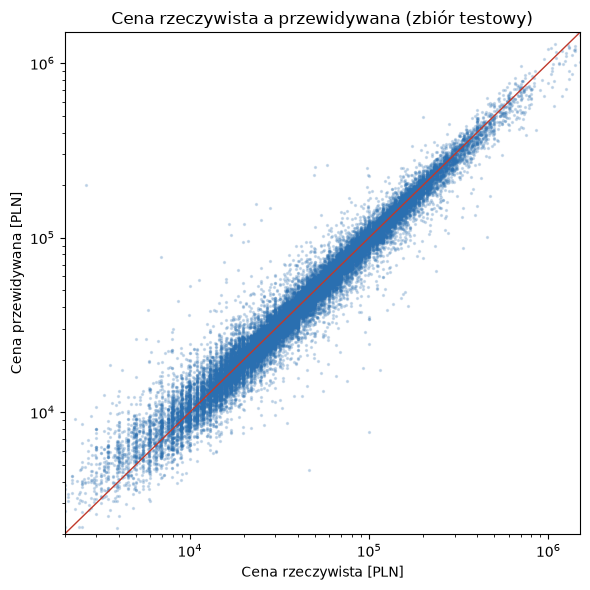

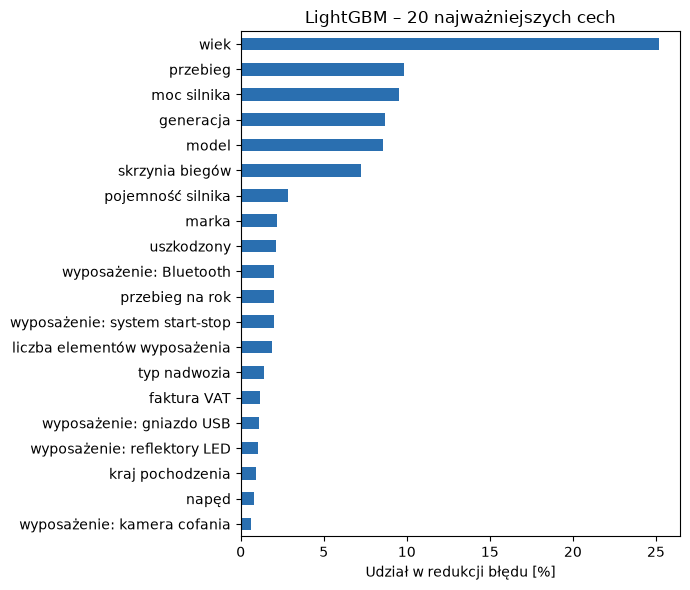

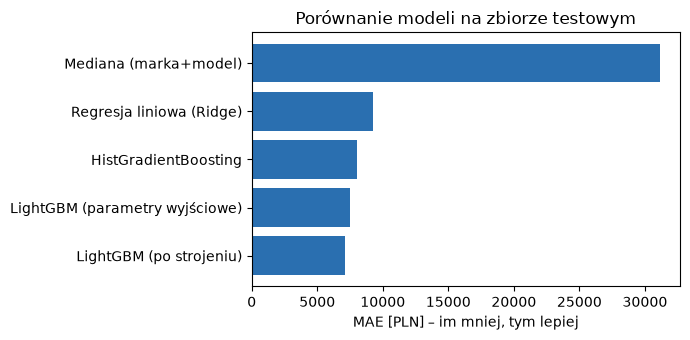

In [8]:
# Cena rzeczywista vs przewidywana (skala logarytmiczna)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, predictions[best], s=2, alpha=0.2, color="#2a6fb0")
lims = [2_000, 1_500_000]
ax.plot(lims, lims, color="#c0392b", lw=1)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="Cena rzeczywista [PLN]", ylabel="Cena przewidywana [PLN]",
       title="Cena rzeczywista a przewidywana (zbiór testowy)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "actual_vs_predicted.png", dpi=150)

# Ważność cech (liczba zysków informacyjnych, top 20)
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=X_train_lgb.columns)
imp = (imp / imp.sum() * 100).sort_values(ascending=False).head(20)
imp.round(2).rename("udział [%]").rename_axis("cecha").to_csv(RESULTS_DIR / "feature_importance_top20.csv", sep=";", decimal=",")
FEATURE_LABELS = {
    "age": "wiek", "mileage_km": "przebieg", "power_km": "moc silnika", "generation": "generacja",
    "vehicle_model": "model", "transmission": "skrzynia biegów", "engine_cm3": "pojemność silnika",
    "vehicle_brand": "marka", "damaged": "uszkodzony", "mileage_per_year": "przebieg na rok",
    "equipment_count": "liczba elementów wyposażenia", "body_type": "typ nadwozia", "vat": "faktura VAT",
    "country_of_origin": "kraj pochodzenia", "drive_type": "napęd", "fuel_type": "rodzaj paliwa",
    "seller_type": "typ sprzedawcy", "voivodeship": "województwo", "color": "kolor",
    "fuel_city_l100": "zużycie paliwa w mieście", "no_accident": "bezwypadkowy",
    "eq_bluetooth_interface": "wyposażenie: Bluetooth", "eq_start/stop_system": "wyposażenie: system start-stop",
    "eq_usb_socket": "wyposażenie: gniazdo USB", "eq_front_lamps_in_led_technology": "wyposażenie: reflektory LED",
    "eq_rear_parking_camera": "wyposażenie: kamera cofania",
}
imp.index = [FEATURE_LABELS.get(c, c.replace("eq_", "wyposażenie: ").replace("_", " ")) for c in imp.index]
fig, ax = plt.subplots(figsize=(7, 6))
imp[::-1].plot.barh(ax=ax, color="#2a6fb0")
ax.set(xlabel="Udział w redukcji błędu [%]", title="LightGBM – 20 najważniejszych cech")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_importance.png", dpi=150)

# Porównanie modeli (MAE)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(res["model"][::-1], res["MAE [PLN]"][::-1], color="#2a6fb0")
ax.set(xlabel="MAE [PLN] – im mniej, tym lepiej", title="Porównanie modeli na zbiorze testowym")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "model_comparison_mae.png", dpi=150)

## 7. Zapis modelu i przykład wyceny

In [9]:
for model, fname in [(lgbm, "lightgbm_model.joblib"), (lgbm_seg, "lightgbm_model_segment.joblib")]:
    joblib.dump({"model": model, "cat_dtypes": {c: X_train_lgb[c].dtype for c in CAT_COLS},
                 "columns": list(X_train_lgb.columns)}, RESULTS_DIR / fname, compress=3)

# Przykład: wycena kilku losowych aut z segmentu salonu (zbiór testowy)
sample = X_test[seg_test].sample(6, random_state=1)
example = pd.DataFrame({
    "marka": sample["vehicle_brand"], "model": sample["vehicle_model"],
    "rok": (REFERENCE_YEAR - sample["age"]).astype(int), "przebieg [km]": sample["mileage_km"].astype(int),
    "cena ogłoszenia [PLN]": y_test.loc[sample.index].round(0).astype(int),
    "wycena modelu [PLN]": np.exp(lgbm.predict(X_test_lgb.loc[sample.index])).round(-2).astype(int),
})
example["różnica [%]"] = ((example["wycena modelu [PLN]"] / example["cena ogłoszenia [PLN]"] - 1) * 100).round(1)
print(example.to_string(index=False))
example.to_csv(RESULTS_DIR / "example_valuations.csv", index=False, sep=";", decimal=",")
print(f"Wyniki zapisano w: {RESULTS_DIR}")

        marka   model  rok  przebieg [km]  cena ogłoszenia [PLN]  wycena modelu [PLN]  różnica [%]
Mercedes-Benz     GLB 2020          53743                 159900               170200          6.4
      Citroën      C5 2012         196000                  26000                25700         -1.2
         Audi      A3 2010         200800                  42900                38400        -10.5
         Opel  Zafira 2012         215000                  36900                30100        -18.4
Mercedes-Benz Klasa C 2011         235171                  36000                38300          6.4
         Audi      A3 2008         194000                  19500                20200          3.6
Wyniki zapisano w: E:\Praca Dyplomowa\model\results
